In [1]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
from sklearn import metrics
from PIL import Image
import json
import random
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import keras_tuner
import gc
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
train_ds, valid_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_train/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    shuffle=False,
    image_size=(64,64)
)
# num_files = train_ds.cardinality().numpy() * 16
# train_ds = train_ds.shuffle(buffer_size=4)
# valid_ds = train_ds.take(0.3*num_files)
# train_ds = train_ds.skip(0.3*num_files)
# valid_ds = tf.data.Dataset.sample_from_datasets([train_ds], [0.3])

Found 3404 files belonging to 2 classes.
Using 2724 files for training.
Using 680 files for validation.
Found 1432 files belonging to 2 classes.


In [3]:
def build_model(hp):
    model = keras.models.Sequential()
    model.add(keras.Input(shape=(64,64,3)))

    for i in range(hp.Int("num_layers", 1, 3)):
        model.add(layers.Conv2D(
            filters=hp.Int(f"filters_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
            kernel_size=hp.Int(f"kernel_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
            activation='relu', padding="same"))
        model.add(layers.MaxPooling2D(pool_size=2, strides=2))

    model.add(layers.Flatten())
    for i in range(hp.Int("dense_layers", 1, 3)):
        model.add(layers.Dense(
            units=hp.Int(f"units_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
            activation="relu"))

    model.add(layers.Dense(units=1, activation='sigmoid'))

    model.compile(
        loss=tf.keras.losses.binary_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.binary_accuracy]
        # metrics=[tf.keras.metrics.RecallAtPrecision(0.8)]
    )
    return model
# tmodel=build_model
# print(tmodel)

In [16]:
tuner = keras_tuner.RandomSearch(
    hypermodel=build_model,
    objective=keras_tuner.Objective("val_binary_accuracy", direction="max"),
    max_trials=10,
    overwrite=True,
    directory="./models/",
    project_name="model2",
)
# tuner = keras_tuner.Hyperband(
#     hypermodel=build_model,
#     objective='val_binary_accuracy',
#     # objective=keras_tuner.Objective("val_recall_at_precision", direction="max"),
#     max_epochs=50,
#     factor=3,
#     overwrite=True,
#     directory="./models/",
#     project_name="model2",
#     seed=42
# )
stop_early = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy",
                                           patience=10)

In [17]:
tuner.search(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early]
    )

Trial 10 Complete [00h 05m 32s]
val_binary_accuracy: 0.7397058606147766

Best val_binary_accuracy So Far: 0.8235294222831726
Total elapsed time: 00h 17m 38s
INFO:tensorflow:Oracle triggered exit


In [18]:
models = tuner.get_best_models(2)
best_model = models[0]
best_model.build()
best_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 16)        3088      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 8)         32776     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 8)        0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 16, 16, 8)         4104      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 8, 8, 8)          0

In [19]:
best_model.evaluate(test_ds)

90/90 [==============================] - 1s 11ms/step - loss: 0.4538 - binary_accuracy: 0.8408


[0.4538347125053406, 0.840782105922699]

In [22]:
best_model.save("./trained_models/model2")

INFO:tensorflow:Assets written to: ./trained_models/model2\assets


INFO:tensorflow:Assets written to: ./trained_models/model2\assets


In [8]:
saved_model2 = keras.models.load_model("./trained_models/model1/")
saved_model2.evaluate(test_ds)
saved_model2.summary()

90/90 [==============================] - 1s 7ms/step - loss: 1.4191 - binary_accuracy: 0.6578
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 8)         224       
                                                                 
 dropout (Dropout)           (None, 64, 64, 8)         0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 8)        0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        4672      
                                                                 
 dropout_1 (Dropout)         (None, 32, 32, 64)        0         
                                                                 
 max_pooling2d_1 (MaxPooling

In [20]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1
    return filtered_data, TP, FP, TN, FN

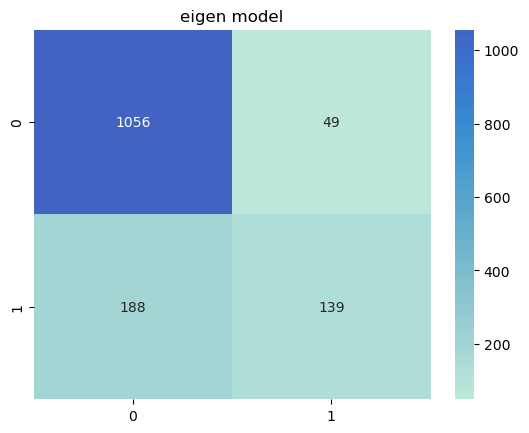

In [21]:
filtered_data, TP, FP, TN, FN = test_model(best_model, test_ds)

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('eigen model')

plt.show()

In [9]:
model1 = keras.models.Sequential()
model1.add(keras.Input(shape=(64,64,3)))

model1.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding="same"))
model1.add(layers.Dropout(0.3))
model1.add(layers.MaxPooling2D(pool_size=2, strides=2))
model1.add(layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding="same"))
model1.add(layers.Dropout(0.3))
model1.add(layers.MaxPooling2D(pool_size=2, strides=2))

model1.add(layers.Flatten())

model1.add(layers.Dense(units=64, activation="relu"))
model1.add(layers.Dense(units=8, activation="relu"))

model1.add(layers.Dense(units=1, activation='sigmoid'))

model1.compile(
    loss=tf.keras.losses.binary_crossentropy,
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=[keras.metrics.binary_accuracy, keras.metrics.Recall()]
)

In [10]:
history = model1.fit(
    train_ds, 
    epochs=50, 
    batch_size=16,
    # steps_per_epoch=100,
    validation_data=valid_ds, 
    use_multiprocessing=True)

Epoch 1/50
171/171 [==============================] - 2s 10ms/step - loss: 2.8508 - binary_accuracy: 0.7522 - recall: 0.0270 - val_loss: 0.6643 - val_binary_accuracy: 0.7397 - val_recall: 0.0000e+00
Epoch 2/50
171/171 [==============================] - 2s 9ms/step - loss: 0.6453 - binary_accuracy: 0.7687 - recall: 0.0000e+00 - val_loss: 0.6387 - val_binary_accuracy: 0.7397 - val_recall: 0.0000e+00
Epoch 3/50
171/171 [==============================] - 2s 9ms/step - loss: 0.6187 - binary_accuracy: 0.7687 - recall: 0.0000e+00 - val_loss: 0.6188 - val_binary_accuracy: 0.7397 - val_recall: 0.0000e+00
Epoch 4/50
171/171 [==============================] - 2s 10ms/step - loss: 0.5980 - binary_accuracy: 0.7687 - recall: 0.0000e+00 - val_loss: 0.6039 - val_binary_accuracy: 0.7397 - val_recall: 0.0000e+00
Epoch 5/50
171/171 [==============================] - 2s 12ms/step - loss: 0.5823 - binary_accuracy: 0.7687 - recall: 0.0000e+00 - val_loss: 0.5934 - val_binary_accuracy: 0.7397 - val_recall: 0.

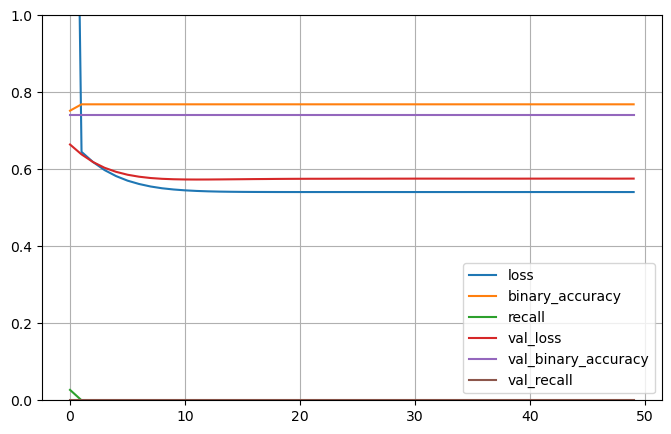

In [11]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

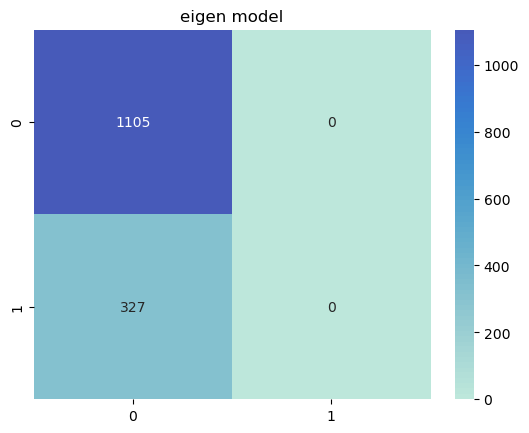

In [16]:
filtered_data, TP, FP, TN, FN = test_model(model1, test_ds)

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=2000, fmt='g')
plt.title('eigen model')

plt.show()